In [213]:
import sys
print(sys.executable)

c:\Users\chenj\anaconda3\python.exe


In [214]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Data Collection

In [215]:
funds = ["FSPTX", "FSELX", "FSCSX", "FSPHX", "FBIOX", "FSMEX", "FPHAX", "FIDSX", "FSRBX", "FSPCX", "FSENX", "FSDAX", "FSRFX", "FSCPX", "FSAVX", "FSRPX", "FDFAX", "FSTCX", "FWRLX"]
prices = yf.download(tickers=funds + ["SPY", "XLK"], start="2015-01-01", end="2026-10-01", auto_adjust=False, progress=False)

In [216]:
prices = prices["Adj Close"]
prices

Ticker,FBIOX,FDFAX,FIDSX,FPHAX,FSAVX,FSCPX,FSCSX,FSDAX,FSELX,FSENX,...,FSPCX,FSPHX,FSPTX,FSRBX,FSRFX,FSRPX,FSTCX,FWRLX,SPY,XLK
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,11.000016,46.551399,4.670525,10.712302,20.123484,19.435738,4.505636,6.041414,2.884585,36.330265,...,26.004528,10.029358,4.799392,11.604659,42.423233,4.205565,28.825598,3.914888,169.267487,18.041683
2015-01-05,11.020168,46.056793,4.580223,10.622028,19.604450,19.080351,4.434749,5.946351,2.837291,34.780521,...,25.517298,9.970016,4.720870,11.296417,41.462196,4.124608,28.381538,3.837536,166.210617,17.766275
2015-01-06,10.810785,45.965549,4.512496,10.556833,19.371325,18.899742,4.365809,5.905758,2.785574,34.280083,...,25.207958,9.872952,4.676362,11.035931,40.682724,4.080834,28.109369,3.798860,164.645050,17.552063
2015-01-07,11.174009,46.618637,4.551347,10.757437,19.718815,19.243481,4.386451,5.963822,2.811092,34.280083,...,25.455433,10.130100,4.708274,11.118419,40.833309,4.156615,28.276489,3.833239,166.696762,17.700697
2015-01-08,11.334734,47.358154,4.610148,10.963057,20.066299,19.523130,4.462013,6.089203,2.889348,35.038815,...,25.803446,10.312268,4.812408,11.292075,41.719063,4.208389,28.682352,3.893402,169.654739,18.089771
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,29.000000,91.109657,16.469999,34.869999,51.939999,61.090000,24.660000,25.860001,63.730000,90.510002,...,91.459999,29.990000,58.070000,36.110001,112.410004,16.629999,67.925964,15.230000,767.179993,194.710007
2026-09-25,28.920000,91.507607,16.610001,35.000000,52.450001,61.259998,24.530001,26.059999,64.379997,89.889999,...,91.919998,29.959999,58.459999,36.509998,113.059998,16.719999,67.727005,15.320000,771.349976,196.270004
2026-09-28,28.969999,91.855804,16.410000,34.990002,51.380001,60.459999,24.299999,25.490000,63.840000,89.889999,...,91.730003,30.139999,57.889999,36.000000,112.720001,16.680000,66.851562,15.060000,765.609985,194.529999


In [217]:
log_returns = np.log(prices).diff().dropna()
market_log_returns = log_returns["SPY"]
xlk_log_returns = log_returns["XLK"]
log_returns = log_returns[funds]
print(log_returns)

Ticker         FSPTX     FSELX     FSCSX     FSPHX     FBIOX     FSMEX  \
Date                                                                     
2015-01-05 -0.016496 -0.016531 -0.015858 -0.005934  0.001830  0.003872   
2015-01-06 -0.009473 -0.018396 -0.015668 -0.009783 -0.019183 -0.008020   
2015-01-07  0.006801  0.009119  0.004717  0.025712  0.033046  0.019293   
2015-01-08  0.021876  0.027458  0.017079  0.017823  0.014281  0.018678   
2015-01-09 -0.005074  0.000942 -0.009472 -0.004426  0.000433 -0.004009   
...              ...       ...       ...       ...       ...       ...   
2026-09-24  0.000517 -0.004071 -0.005258  0.015119  0.004839  0.022781   
2026-09-25  0.006694  0.010148 -0.005286 -0.001001 -0.002762 -0.000176   
2026-09-28 -0.009798 -0.008423 -0.009421  0.005990  0.001727  0.010156   
2026-09-29 -0.004328  0.010285  0.001234 -0.001993 -0.003112  0.001914   
2026-09-30  0.005364  0.000465  0.011849 -0.007676 -0.001733 -0.008206   

Ticker         FPHAX     FIDSX     FS

## Performace Summary

### Part 1

In [218]:
mean_returns = log_returns.mean() * 252
volatilities = log_returns.std() * np.sqrt(252)
sharpe_ratio = mean_returns / volatilities

absolute = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
    "Sharpe Ratio": sharpe_ratio,
})

summary_abs = absolute.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_abs.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary_abs.round(4)

,Mean Return,Volatility,Sharpe Ratio
Min,0.0562,0.1482,0.2480
Q1,0.0826,0.1941,0.3823
Mean,0.1119,0.2263,0.4927
Median,0.0995,0.2181,0.4868
Q3,0.1158,0.2441,0.5612
Max,0.2653,0.3431,0.8405


### Part 2

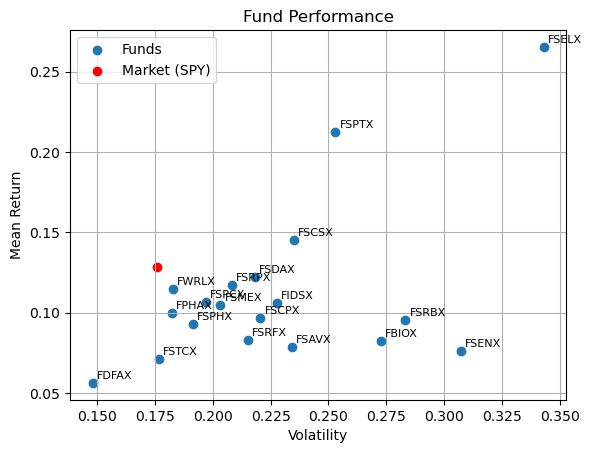

0.731361317526649


,Mean Return,Volatility,Sharpe Ratio
Ticker,,,
FSPTX,0.212654,0.253010,0.840498
FSELX,0.265296,0.343075,0.773289
FSCSX,0.144971,0.235144,0.616520


In [219]:
market_mean_return = market_log_returns.mean() * 252
market_volatility = market_log_returns.std() * np.sqrt(252)

fund_metrics = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
})
plt.scatter(fund_metrics["Volatility"], fund_metrics["Mean Return"], label="Funds")
for t in fund_metrics.index:
    plt.annotate(t, (fund_metrics.loc[t, "Volatility"], fund_metrics.loc[t, "Mean Return"]),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.scatter(market_volatility, market_mean_return, color="red", marker="o", label="Market (SPY)")
plt.xlabel("Volatility")
plt.ylabel("Mean Return")
plt.title("Fund Performance")
plt.grid(True)
plt.legend()
plt.show()

indices = fund_metrics["Mean Return"] > market_mean_return
outperforms_market = fund_metrics[indices].copy()
outperforms_market

market_sharpe_ratio = market_mean_return / market_volatility
print(market_sharpe_ratio)
outperforms_market["Sharpe Ratio"] = outperforms_market["Mean Return"] / outperforms_market["Volatility"]
outperforms_market

Only the three technology-oriented funds, Software (FSCSX, 14.5%), Technology (FSPTX, 21.3%) and Semiconductors (FSLX, 26.5%), outperform SPY's 12.9% mean return, but each does so with higher volatility (23.5%-34.3% vs. 17.6% for SPY).

### Part 3

#### (a)

In [220]:
combined = log_returns.copy()
combined["SPY"] = market_log_returns
covariances = combined.cov() * 252
betas = (covariances["SPY"] / covariances.loc["SPY", "SPY"]).drop("SPY")

alphas = mean_returns - betas * market_mean_return
alphas

treynor = (mean_returns) / betas
treynor

tracking_error = log_returns.sub(market_log_returns, axis=0)
tracking_error = tracking_error.std() * np.sqrt(252)

information_ratio = (mean_returns - market_mean_return) / tracking_error
information_ratio

relative = pd.DataFrame({
    "Jensen's Alpha": alphas,
    "Beta": betas,
    "Treynor Ratio": treynor,
    "Tracking Error": tracking_error,
    "Information Ratio": information_ratio,
})

summary = relative.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.062318,0.595044,0.071747,0.082447,-0.569804
Q1,-0.045769,0.878273,0.084866,0.123740,-0.298564
Mean,-0.016218,0.997018,0.110406,0.144635,-0.134738
Median,-0.015994,1.001510,0.109662,0.132159,-0.186634
Q3,-0.001411,1.107424,0.126945,0.142102,-0.136138
Max,0.064266,1.564427,0.169580,0.248289,0.682078


(b)

In [221]:
area = pd.Series({
    "FSPTX": "Technology", "FSELX": "Semiconductors", "FSCSX": "Software",
    "FSPHX": "Health Care", "FBIOX": "Biotechnology", "FSMEX": "Medical Technology",
    "FPHAX": "Pharmaceuticals", "FIDSX": "Financials", "FSRBX": "Banking",
    "FSPCX": "Insurance", "FSENX": "Energy", "FSDAX": "Aerospace/Defense",
    "FSRFX": "Transportation", "FSCPX": "Consumer Discretionary", "FSAVX": "Automotive",
    "FSRPX": "Retailing", "FDFAX": "Consumer Staples", "FSTCX": "Telecommunications",
    "FWRLX": "Wireless",
})

top5 = alphas.sort_values(ascending=False).index[:5]
top5_table = pd.concat([area[top5].rename("Area"), relative.loc[top5, ["Jensen's Alpha", "Beta"]], absolute.loc[top5]], axis=1)
top5_table["Mean Return Rank"] = mean_returns.rank(ascending=False)[top5].astype(int)
top5_table["Sharpe Rank"] = sharpe_ratio.rank(ascending=False)[top5].astype(int)
top5_table.round(4)

,Area,Jensen's Alpha,Beta,Mean Return,Volatility,Sharpe Ratio,Mean Return Rank,Sharpe Rank
Ticker,,,,,,,,
FSELX,Semiconductors,0.0643,1.5644,0.2653,0.3431,0.7733,1,2
FSPTX,Technology,0.0469,1.2903,0.2127,0.2530,0.8405,2,1
FPHAX,Pharmaceuticals,0.0096,0.6996,0.0995,0.1822,0.5459,10,7
FSDAX,Aerospace/Defense,-0.0004,0.9546,0.1223,0.2181,0.5605,4,6
FSCSX,Software,-0.0008,1.1342,0.1450,0.2351,0.6165,3,4


### 4.

#### (a)

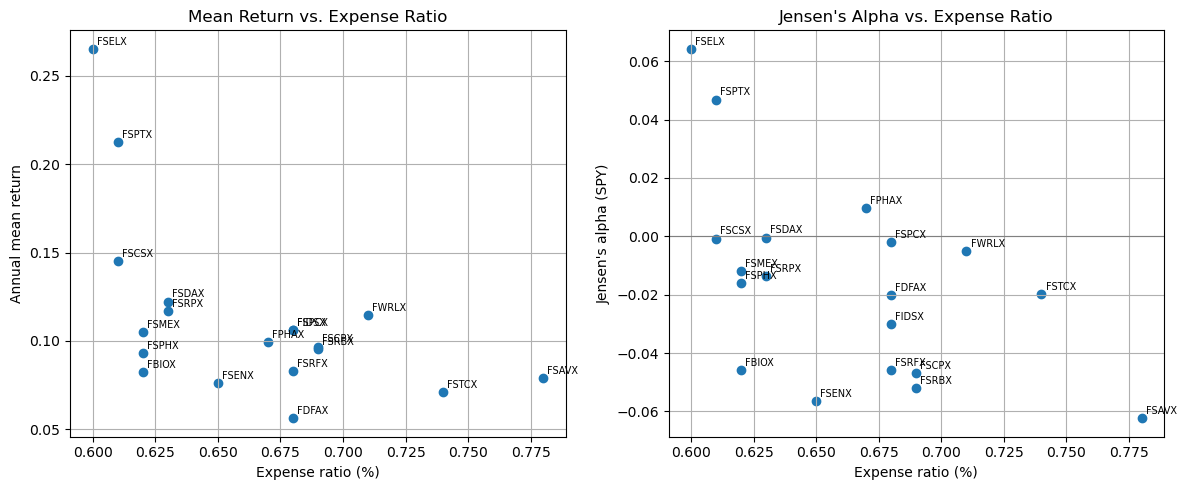

In [222]:
expense = pd.Series({
    "FSPTX": 0.61, "FSELX": 0.60, "FSCSX": 0.61, "FSPHX": 0.62, "FBIOX": 0.62,
    "FSMEX": 0.62, "FPHAX": 0.67, "FIDSX": 0.68, "FSRBX": 0.69, "FSPCX": 0.68,
    "FSENX": 0.65, "FSDAX": 0.63, "FSRFX": 0.68, "FSCPX": 0.69, "FSAVX": 0.78,
    "FSRPX": 0.63, "FDFAX": 0.68, "FSTCX": 0.74, "FWRLX": 0.71,
})

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(expense[funds], mean_returns[funds])
ax[0].set_xlabel("Expense ratio (%)")
ax[0].set_ylabel("Annual mean return")
ax[0].set_title("Mean Return vs. Expense Ratio")
ax[0].grid(True)

ax[1].scatter(expense[funds], alphas[funds])
ax[1].axhline(0, color="gray", linewidth=0.8)
ax[1].set_xlabel("Expense ratio (%)")
ax[1].set_ylabel("Jensen's alpha (SPY)")
ax[1].set_title("Jensen's Alpha vs. Expense Ratio")
ax[1].grid(True)

for t in funds:
    ax[0].annotate(t, (expense[t], mean_returns[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].annotate(t, (expense[t], alphas[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.tight_layout()
plt.savefig("fig_1_4.png", dpi=300)
plt.show()

#### (b)

In [223]:
print("Corr(ER, Mean): ", round(expense[funds].corr(mean_returns[funds]), 4))
print("Corr(ER, Alpha):", round(expense[funds].corr(alphas[funds]), 4))

Corr(ER, Mean):  -0.5501
Corr(ER, Alpha): -0.5391


### 5.

#### (a)

In [224]:
xlk_mean_return = xlk_log_returns.mean() * 252

returns_xlk = log_returns[funds].copy()
returns_xlk["XLK"] = xlk_log_returns
cov_xlk = returns_xlk.cov() * 252
betas_xlk = (cov_xlk["XLK"] / cov_xlk.loc["XLK", "XLK"]).drop("XLK")

alphas_xlk = mean_returns - betas_xlk * xlk_mean_return
treynor_xlk = mean_returns / betas_xlk
tracking_error_xlk = log_returns[funds].sub(xlk_log_returns, axis=0).std() * np.sqrt(252)
information_ratio_xlk = (mean_returns - xlk_mean_return) / tracking_error_xlk

relative_xlk = pd.DataFrame({
    "Jensen's Alpha": alphas_xlk,
    "Beta": betas_xlk,
    "Treynor Ratio": treynor_xlk,
    "Tracking Error": tracking_error_xlk,
    "Information Ratio": information_ratio_xlk,
})
summary_xlk = relative_xlk.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_xlk.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
display(summary_xlk.round(4))

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.0647,0.3177,0.1117,0.0596,-0.7486
Q1,-0.0329,0.5456,0.1466,0.1627,-0.6535
Mean,-0.0194,0.6449,0.1736,0.1845,-0.4806
Median,-0.0168,0.6089,0.1731,0.1838,-0.5125
Q3,-0.0020,0.6858,0.1934,0.2063,-0.4414
Max,0.0166,1.2688,0.2411,0.2976,0.3633


#### (b)

In [225]:
compare = pd.DataFrame({
    "Alpha_SPY": alphas[funds],
    "Rank_SPY": alphas[funds].rank(ascending=False).astype(int),
    "Alpha_XLK": alphas_xlk,
    "Rank_XLK": alphas_xlk.rank(ascending=False).astype(int),
}).sort_values("Rank_SPY")
display(compare.round(4))

,Alpha_SPY,Rank_SPY,Alpha_XLK,Rank_XLK
Ticker,,,,
FSELX,0.0643,1,0.0071,3
FSPTX,0.0469,2,0.0044,5
FPHAX,0.0096,3,0.0134,2
FSDAX,-0.0004,4,0.0061,4
FSCSX,-0.0008,5,-0.0292,13
FSPCX,-0.0020,6,0.0166,1
FWRLX,-0.0051,7,-0.0201,12
FSMEX,-0.0118,8,-0.0162,9
FSRPX,-0.0136,9,-0.0186,11


### Mean-Variance Efficient Frontier

#### 1. Monthly Data and Split

In [226]:
tickers_2 = ["FSPTX","FIDSX","FSCPX"]
prices_2 = yf.download(tickers=tickers_2, start="2015-01-01", end="2026-10-01", interval ="1mo", auto_adjust=False, progress=False)["Adj Close"][tickers_2]

log_returns_2 = np.log(prices_2).diff().dropna()

half = len(log_returns_2) // 2
r1 = log_returns_2.iloc[:half]
r2 = log_returns_2.iloc[half:]
print(len(r1), r1.index[0],r1.index[-1])
print(len(r2), r2.index[0],r2.index[-1])
returns_1 = r1
returns_2 = r2
print(returns_1)
print(returns_2)

70 2015-02-01 00:00:00 2020-11-01 00:00:00
70 2020-12-01 00:00:00 2026-09-01 00:00:00
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2015-02-01  0.068048  0.062110  0.077279
2015-03-01 -0.002817  0.000000 -0.004837
2015-04-01  0.012982  0.002024 -0.008784
2015-05-01  0.030156  0.014055  0.005568
2015-06-01 -0.027835 -0.009684  0.015082
...              ...       ...       ...
2020-07-01  0.071444  0.007547  0.065053
2020-08-01  0.116707  0.032062  0.086996
2020-09-01 -0.032826 -0.040873 -0.015778
2020-10-01 -0.038554  0.027433 -0.032146
2020-11-01  0.120733  0.162027  0.110556

[70 rows x 3 columns]
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2020-12-01  0.066881  0.078762  0.057194
2021-01-01  0.005197 -0.010875 -0.001814
2021-02-01  0.018342  0.112689  0.028788
2021-03-01 -0.001091  0.066147  0.034254
2021-04-01  0.031295  0.063721  0.065544
...              ...       ...       ...
2026-05-01  0.168246 -0.019343

#### 2. Mean Vectors

In [227]:
mu1 = r1.mean()
mu2 = r2.mean()
pd.DataFrame({"μ1 (monthly)": mu1, "μ2 (monthly)": mu2,
              "μ1 (annualized)": mu1 * 12, "μ2 (annualized)": mu2 * 12}).round(4)

,μ1 (monthly),μ2 (monthly),μ1 (annualized),μ2 (annualized)
Ticker,,,,
FSPTX,0.0193,0.0165,0.2310,0.1981
FIDSX,0.0063,0.0124,0.0750,0.1485
FSCPX,0.0115,0.0050,0.1377,0.0605


#### 3. Covariance Matrices

In [228]:
sigma1 = r1.std()
sigma2 = r2.std()
cov1 = r1.cov()
cov2 = r2.cov()
print("Standard Deviation (Period 1):", sigma1)
print("Standard Deviation (Period 2):", sigma2)
print("Covariance (Period 1):")
display(cov1.round(5))
print("Covariance (Period 2):")
display(cov2.round(5))
print("Variance (Period 1):")
print(np.diag(cov1))
print("Variance (Period 2):")
print(np.diag(cov2))
cov_FSPTX_FIDSX = cov1.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 1):", cov_FSPTX_FIDSX)
cov_FSPTX_FIDSX_2 = cov2.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 2):", cov_FSPTX_FIDSX_2)
cov_FSPTX_FSCPX = cov1.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 1):", cov_FSPTX_FSCPX)
cov_FSPTX_FSCPX_2 = cov2.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 2):", cov_FSPTX_FSCPX_2)
cov_FIDSX_FSCPX = cov1.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 1):", cov_FIDSX_FSCPX)
cov_FIDSX_FSCPX_2 = cov2.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 2):", cov_FIDSX_FSCPX_2)

# Standard deviations and variances as column vectors
display(pd.DataFrame({"Std Dev (P1)": sigma1, "Std Dev (P2)": sigma2,
                      "Variance (P1)": np.diag(cov1), "Variance (P2)": np.diag(cov2)}).round(5))

# Pairwise covariances as column vectors
pairs = [("FSPTX", "FIDSX"), ("FSPTX", "FSCPX"), ("FIDSX", "FSCPX")]
display(pd.DataFrame({
    "Cov (P1)": [cov1.loc[a, b] for a, b in pairs],
    "Cov (P2)": [cov2.loc[a, b] for a, b in pairs],
}, index=[f"{a}, {b}" for a, b in pairs]).round(5))


Standard Deviation (Period 1): Ticker
FSPTX    0.055841
FIDSX    0.060870
FSCPX    0.051879
dtype: float64
Standard Deviation (Period 2): Ticker
FSPTX    0.068836
FIDSX    0.056209
FSCPX    0.061107
dtype: float64
Covariance (Period 1):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00312,0.00237,0.00248
FIDSX,0.00237,0.00371,0.00258
FSCPX,0.00248,0.00258,0.00269


Covariance (Period 2):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00474,0.00156,0.00330
FIDSX,0.00156,0.00316,0.00218
FSCPX,0.00330,0.00218,0.00373


Variance (Period 1):
[0.00311822 0.00370512 0.00269146]
Variance (Period 2):
[0.00473846 0.00315943 0.00373408]
Covariance between FSPTX and FIDSX (Period 1): 0.0023676765719417626
Covariance between FSPTX and FIDSX (Period 2): 0.0015627546388929236
Covariance between FSPTX and FSCPX (Period 1): 0.0024811045076256954
Covariance between FSPTX and FSCPX (Period 2): 0.0032995317289443273
Covariance between FIDSX and FSCPX (Period 1): 0.0025821559907941894
Covariance between FIDSX and FSCPX (Period 2): 0.0021807823364782906


,Std Dev (P1),Std Dev (P2),Variance (P1),Variance (P2)
Ticker,,,,
FSPTX,0.05584,0.06884,0.00312,0.00474
FIDSX,0.06087,0.05621,0.00371,0.00316
FSCPX,0.05188,0.06111,0.00269,0.00373


,Cov (P1),Cov (P2)
"FSPTX, FIDSX",0.00237,0.00156
"FSPTX, FSCPX",0.00248,0.00330
"FIDSX, FSCPX",0.00258,0.00218


#### 4. The Two Funds

In [229]:
def two_funds(mu, Sigma):
    inv = np.linalg.inv(Sigma)
    ones = np.ones(len(mu))
    w0 = inv @ ones / (ones @ inv @ ones) #GMV portfolio weights
    w1 = inv @ mu - (ones @ inv @ mu) * w0
    return w0, w1

def mv_port(A, mu, sigma):
    w0, w1 = two_funds(mu, sigma)
    w = w0 + 1/A * w1
    return w

A_grid = np.arange(1, 101)
print(A_grid)

w0_1, w1_1 = two_funds(mu1.values, cov1.values)
w0_2, w1_2 = two_funds(mu2.values, cov2.values)

pd.DataFrame({"w0 (P1)": w0_1, "w1 (P1)": w1_1, "w0 (P2)": w0_2, "w1 (P2)": w1_2})

[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]


,w0 (P1),w1 (P1),w0 (P2),w1 (P2)
0,0.248648,9.156059,0.294117,6.449331
1,0.089532,-4.208068,0.634794,3.363430
2,0.661820,-4.947990,0.071090,-9.812761


#### 5. Utopian MVEF

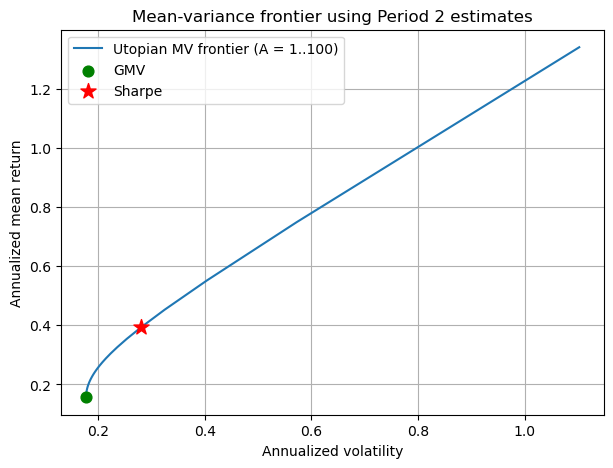

,GMV,Sharpe
w_FSPTX,0.2941,1.5870
w_FIDSX,0.6348,1.3091
w_FSCPX,0.0711,-1.8961
Ann. mean,0.1568,0.3941
Ann. vol,0.1773,0.2811
Ann. Sharpe,0.8845,1.4020
A,NaN,4.9882


In [230]:
def port_stats(w, mu, sigma):
    w = np.asarray(w)
    return w @ mu, np.sqrt(w @ sigma @ w)

mu2v, cov2v = mu2.values, cov2.values

#Utopian Frontier on the A grid
W5 = np.array([mv_port(A, mu2v, cov2v) for A in A_grid])
mean5 = W5 @ mu2v
vol5 = np.sqrt(np.einsum('ij,jk,ik->i', W5, cov2v, W5))

#GMV and Sharpe (tangency) portfolios, computed exactly
mean_gmv, vol_gmv = port_stats(w0_2, mu2v, cov2v)
A_T = np.ones(3) @ np.linalg.inv(cov2v) @ mu2v
w_T = mv_port(A_T, mu2v, cov2v)
mean_T, vol_T = port_stats(w_T, mu2v, cov2v)

#Plot (annualized: mean x12, vol x sqrt(12), applied to every series)
k_m, k_v = 12, np.sqrt(12)
plt.figure(figsize=(7, 5))
plt.plot(vol5*k_v, mean5*k_m, label="Utopian MV frontier (A = 1..100)")
plt.scatter(vol_gmv*k_v, mean_gmv*k_m, color="green", s=60, zorder=3, label="GMV")
plt.scatter(vol_T*k_v, mean_T*k_m, color="red", marker="*", s=130, zorder=3, label="Sharpe")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Mean-variance frontier using Period 2 estimates")
plt.grid(True); plt.legend()
plt.show()

# GMV and Sharpe portfolio summary (period 2, annualized)
pd.DataFrame({
    "GMV": list(w0_2) + [mean_gmv * k_m, vol_gmv * k_v, (mean_gmv * k_m) / (vol_gmv * k_v), np.nan],
    "Sharpe": list(w_T) + [mean_T * k_m, vol_T * k_v, (mean_T * k_m) / (vol_T * k_v), A_T],
}, index=["w_FSPTX", "w_FIDSX", "w_FSCPX", "Ann. mean", "Ann. vol", "Ann. Sharpe", "A"]).round(4)
    

#### 6. Realistic Out-of-Sample Evaluation

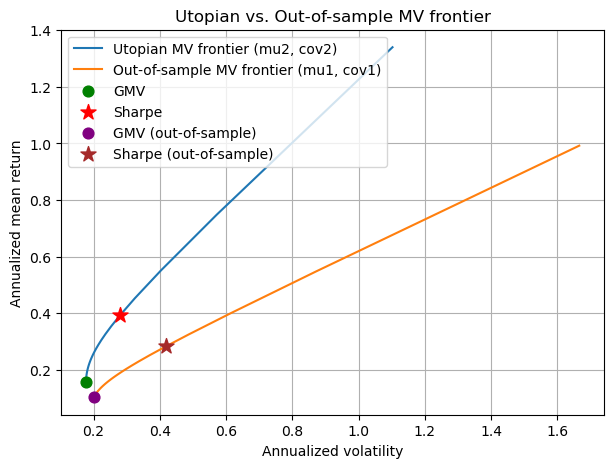

In [231]:
mu1v, cov1v = mu1.values, cov1.values

#build portfolios with period 1 estimates, evaluate them with period 2 estimates
W6 = np.array([mv_port(A, mu1v, cov1v) for A in A_grid])
mean6 = W6 @ mu2v
vol6 = np.sqrt(np.einsum('ij,jk,ik->i', W6, cov2v, W6))

#period-1 GMV and Sharpe portfolios, evaluated with period 2 estimates
mean_gmv1, vol_gmv1 = port_stats(w0_1, mu2v, cov2v)
A_T1 = np.ones(3) @ np.linalg.inv(cov1v) @ mu1v
w_T1 = mv_port(A_T1, mu1v, cov1v)
mean_T1, vol_T1 = port_stats(w_T1, mu2v, cov2v)

plt.figure(figsize=(7, 5))
plt.plot(vol5 * k_v, mean5 * k_m, color="tab:blue", label="Utopian MV frontier (mu2, cov2)")
plt.plot(vol6 * k_v, mean6 * k_m, color="tab:orange", label="Out-of-sample MV frontier (mu1, cov1)")
plt.scatter(vol_gmv*k_v, mean_gmv*k_m, color="green", s=60, zorder=3, label="GMV")
plt.scatter(vol_T*k_v, mean_T*k_m, color="red", marker="*", s=130, zorder=3, label="Sharpe")
plt.scatter(vol_gmv1*k_v, mean_gmv1*k_m, color="purple", s=60, zorder=3, label="GMV (out-of-sample)")
plt.scatter(vol_T1*k_v, mean_T1*k_m, color="brown", marker="*", s=130, zorder=3, label="Sharpe (out-of-sample)")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Utopian vs. Out-of-sample MV frontier")
plt.grid(True); plt.legend()
plt.show()

#### 7. Comparison of Utopian MV vs. Out-of-Sample MV

In [232]:
inv2 = np.linalg.inv(cov2v); one = np.ones(3)
a, b, c = one @ inv2 @ one, one @ inv2 @ mu2v, mu2v @ inv2 @ mu2v
minvar = lambda mu: (a*mu**2 - 2*b*mu + c) / (a*mu**2 - 2*b*mu + c)

gap = vol6 - np.sqrt(minvar(mean6))
print("min gap (should be >= 0):", gap.min(), "| max gap:", gap.max())

min gap (should be >= 0): -0.9407749183796623 | max gap: -0.5191440496274972


#### 8. Parsimonious Build

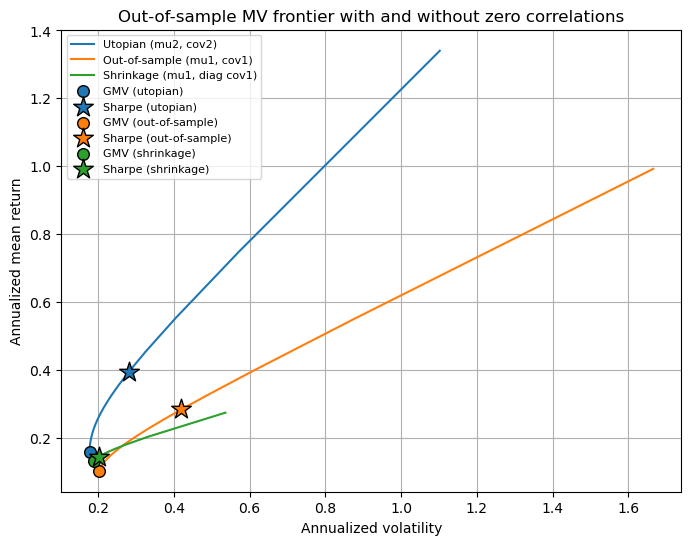

Vol 0.25: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.30: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.40: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.50: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325


,Ann. mean,Ann. vol,Ann. Sharpe
GMV (utopian),0.1568,0.1773,0.8845
Sharpe (utopian),0.3941,0.2811,1.4020
GMV (out-of-sample),0.1026,0.2010,0.5104
Sharpe (out-of-sample),0.2833,0.4198,0.6749
GMV (shrinkage),0.1311,0.1880,0.6971
Sharpe (shrinkage),0.1428,0.2010,0.7104


In [233]:
mu1v, cov1v = mu1.values, cov1.values
cov1_diag = np.diag(np.diag(cov1v))  # zero correlations

def frontier(A_grid, mu_est, S_est, mu_eval, S_eval):
    W = np.array([mv_port(A, mu_est, S_est) for A in A_grid])
    return W @ mu_eval, np.sqrt(np.einsum("ij,jk,ik->i", W, S_eval, W))

mean6, vol6 = frontier(A_grid, mu1v, cov1v, mu2v, cov2v)       # Part 6 (out-of-sample)
mean8, vol8 = frontier(A_grid, mu1v, cov1_diag, mu2v, cov2v)   # Part 8 (shrinkage)

# GMV and Sharpe portfolios for each set of estimates, all evaluated in period 2
def gmv_and_sharpe(mu_est, S_est):
    w0, _ = two_funds(mu_est, S_est)
    A_T = np.ones(3) @ np.linalg.inv(S_est) @ mu_est
    wT = mv_port(A_T, mu_est, S_est)
    return port_stats(w0, mu2v, cov2v), port_stats(wT, mu2v, cov2v)

(m_g1, v_g1), (m_T1, v_T1) = gmv_and_sharpe(mu1v, cov1v)
(m_gd, v_gd), (m_Td, v_Td) = gmv_and_sharpe(mu1v, cov1_diag)

plt.figure(figsize=(8, 6))
plt.plot(vol5 * k_v, mean5 * k_m, color="tab:blue", label="Utopian (mu2, cov2)")
plt.plot(vol6 * k_v, mean6 * k_m, color="tab:orange", label="Out-of-sample (mu1, cov1)")
plt.plot(vol8 * k_v, mean8 * k_m, color="tab:green", label="Shrinkage (mu1, diag cov1)")

plt.scatter(vol_gmv * k_v, mean_gmv * k_m, color="tab:blue", edgecolors="black", s=70, zorder=3, label="GMV (utopian)")
plt.scatter(vol_T * k_v, mean_T * k_m, color="tab:blue", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (utopian)")
plt.scatter(v_g1 * k_v, m_g1 * k_m, color="tab:orange", edgecolors="black", s=70, zorder=3, label="GMV (out-of-sample)")
plt.scatter(v_T1 * k_v, m_T1 * k_m, color="tab:orange", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (out-of-sample)")
plt.scatter(v_gd * k_v, m_gd * k_m, color="tab:green", edgecolors="black", s=70, zorder=3, label="GMV (shrinkage)")
plt.scatter(v_Td * k_v, m_Td * k_m, color="tab:green", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (shrinkage)")

plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Out-of-sample MV frontier with and without zero correlations")
plt.grid(True); plt.legend(fontsize=8)
plt.show()

# mean return of each frontier at the same volatility levels (annualized)
for v in [0.25, 0.30, 0.40, 0.50]:
    m_u = np.interp(v, vol5 * k_v, mean5 * k_m)
    m_6 = np.interp(v, vol6 * k_v, mean6 * k_m)
    m_8 = np.interp(v, vol8 * k_v, mean8 * k_m)
    print(f"Vol {v:.2f}: Utopian {m_u:.4f} | Out-of-sample {m_6:.4f} | Shrinkage {m_8:.4f}")

# GMV and Sharpe summary (evaluated in period 2, annualized)
pd.DataFrame({
    "Ann. mean": [mean_gmv, mean_T, m_g1, m_T1, m_gd, m_Td],
    "Ann. vol":  [vol_gmv, vol_T, v_g1, v_T1, v_gd, v_Td],
}, index=["GMV (utopian)", "Sharpe (utopian)", "GMV (out-of-sample)", "Sharpe (out-of-sample)",
          "GMV (shrinkage)", "Sharpe (shrinkage)"]).mul([k_m, k_v]).assign(
    **{"Ann. Sharpe": lambda d: d["Ann. mean"] / d["Ann. vol"]}).round(4)


Var 1

In [234]:
import scipy

In [235]:
spy = yf.download(tickers = "SPY", start="1994-01-01", end="2026-10-01", interval="1mo", auto_adjust=False, progress=False)["Adj Close"]
print(len(spy), spy.index[0], spy.index[-1])   # expect 393, 1994-01-01, 2026-09-01
spy

393 1994-01-01 00:00:00 2026-09-01 00:00:00


Ticker,SPY
Date,
1994-01-01,27.060352
1994-02-01,26.271158
1994-03-01,25.170357
1994-04-01,25.452578
1994-05-01,25.858252
...,...
2026-05-01,752.667114
2026-06-01,744.920227
2026-07-01,745.179626


In [236]:
s = spy.squeeze().dropna().astype(float)          # Series of 393 monthly adj closes
p = s.values
r = np.diff(np.log(p))                            # 392 monthly log returns
n, dt = len(r), 1/12
T = n*dt
S0, ST_act = p[0], p[-1]

In [237]:
sigma = r.std(ddof=1)/np.sqrt(dt)
mu    = r.mean()/dt + sigma**2/2
print(n, T, S0, ST_act, mu, sigma)

392 32.666666666666664 27.060352325439453 762.6300048828125 0.11343364093804045 0.14985617348900096


In [250]:
print(spy.squeeze().round(6).tolist())

[27.060352, 26.271158, 25.170357, 25.452578, 25.858252, 25.265751, 26.082474, 27.076777, 26.39296, 27.143215, 26.06249, 26.252281, 27.134558, 28.241915, 29.028393, 29.888266, 31.074039, 31.702656, 32.722389, 32.868053, 34.260906, 34.160194, 35.679661, 36.241016, 37.530399, 37.650116, 38.298389, 38.714664, 39.593494, 39.942802, 38.147923, 38.882614, 41.055084, 42.38245, 45.476543, 44.394287, 47.137264, 47.58815, 45.488426, 48.336155, 51.391342, 53.503643, 57.744595, 54.75322, 57.386368, 55.980179, 58.146412, 59.255363, 60.018486, 64.177391, 67.308228, 68.169159, 66.75338, 69.595291, 68.65477, 58.962116, 62.714451, 67.799431, 71.5746, 76.257187, 78.943413, 76.411797, 79.580399, 82.602425, 80.713707, 85.183472, 82.540939, 82.113457, 80.279305, 85.423401, 86.845848, 91.805534, 87.234802, 85.906578, 94.232101, 90.922638, 89.49308, 91.254501, 89.821609, 95.690598, 90.440796, 90.017708, 83.29763, 82.862289, 86.546318, 78.290855, 73.903625, 80.217995, 79.768333, 77.867477, 77.073532, 72.500633

var 2

In [238]:
rng = np.random.default_rng(535)
Z = rng.standard_normal((1000, n))
def simulate(mu, sigma, Z):
    inc = (mu - sigma**2/2)*dt + sigma*np.sqrt(dt)*Z
    return S0*np.exp(np.concatenate([np.zeros((Z.shape[0],1)), np.cumsum(inc, axis=1)], axis=1))
paths = simulate(mu, sigma, Z)
ST = paths[:, -1]
print("E[S_T] sim/theory:", ST.mean(), S0*np.exp(mu*T))
print("Var[S_T] sim/theory:", ST.var(ddof=1), S0**2*np.exp(2*mu*T)*(np.exp(sigma**2*T)-1))

E[S_T] sim/theory: 1064.273009888275 1100.5535727165948
Var[S_T] sim/theory: 1110611.6615625354 1311199.3617280088


Var 3

closest (price): 360 677.165444254099 | closest (log): 755 | median dist: 2828.5291268320666


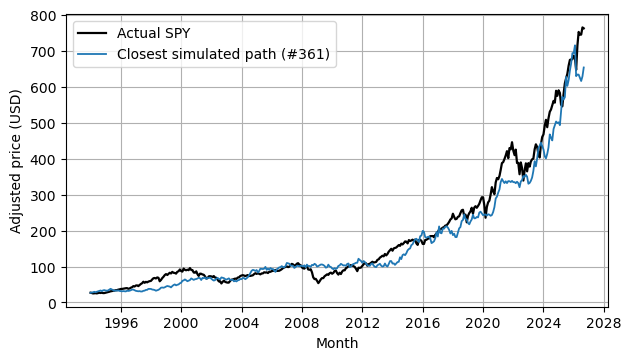

In [239]:
d2 = np.linalg.norm(paths - p, axis=1)
d2log = np.linalg.norm(np.log(paths) - np.log(p), axis=1)
best = d2.argmin()
print("closest (price):", best, d2.min(), "| closest (log):", d2log.argmin(), "| median dist:", np.median(d2))
plt.figure(figsize=(7,3.8))
plt.plot(s.index, p, "k", lw=1.6, label="Actual SPY")
plt.plot(s.index, paths[best], lw=1.3, label=f"Closest simulated path (#{best+1})")
plt.legend(); plt.grid(True); plt.xlabel("Month"); plt.ylabel("Adjusted price (USD)")
plt.savefig("fig_3_3.png", dpi=300, bbox_inches="tight"); plt.show()

var 4

In [240]:
var99 = lambda x: np.mean(x) - np.quantile(x, 0.01)
pnl = 100*(ST - S0)
print("mean PNL", pnl.mean(), "| q01", np.quantile(pnl, .01), "| VaR (mean-q01)", var99(pnl), "| -q01", -np.quantile(pnl, .01))

mean PNL 103721.26575628355 | q01 7583.274932229932 | VaR (mean-q01) 96137.99082405362 | -q01 -7583.274932229932


var 5

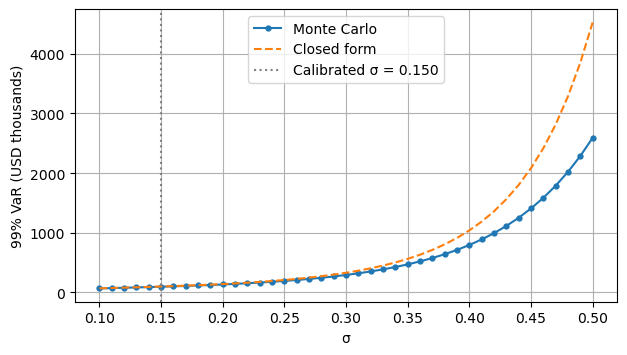

0.1 67885 69617
0.2 134031 141234
0.3 293368 330273
0.4 795333 1040193
0.5 2590365 4525573


In [241]:
grid = np.round(np.arange(0.10, 0.5001, 0.01), 2)
sweep = []
for sg in grid:
    mu_s = r.mean()/dt + sg**2/2                  # recalibrate mu for each sigma
    sweep.append(var99(100*(simulate(mu_s, sg, Z)[:, -1] - S0)))
sweep = np.array(sweep)
z = stats.norm.ppf(0.01); mT = r.mean()*n
closed = 100*S0*(np.exp(mT + grid**2*T/2) - np.exp(mT + grid*np.sqrt(T)*z))
plt.figure(figsize=(7,3.8))
plt.plot(grid, sweep/1e3, "o-", ms=3.5, label="Monte Carlo")
plt.plot(grid, closed/1e3, "--", label="Closed form")
plt.axvline(sigma, color="gray", ls=":", label=f"Calibrated σ = {sigma:.3f}")
plt.xlabel("σ"); plt.ylabel("99% VaR (USD thousands)"); plt.grid(True); plt.legend()
plt.savefig("fig_3_5.png", dpi=300, bbox_inches="tight"); plt.show()
for sg in (0.10, 0.20, 0.30, 0.40, 0.50):
    i = list(grid).index(sg); print(sg, round(sweep[i]), round(closed[i]))

var 6

VaR hist 0.11954522759669355 | VaR sim 0.10044947726189062 | Gaussian 0.10063722989089323
q01 hist/sim -0.11102812721572207 -0.09201480765460479 | min -0.18054637693414133
skew hist/sim -0.7229691488175114 -0.0009683351190402673 | ex.kurt 1.2739737574991707 -0.010387659081747547


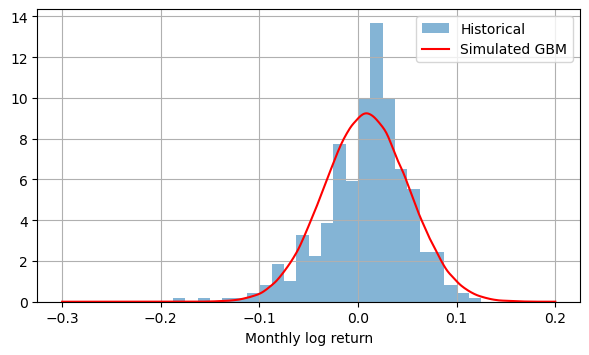

In [242]:
sim_r = np.diff(np.log(paths), axis=1).ravel()
print("VaR hist", var99(r), "| VaR sim", var99(sim_r), "| Gaussian", -z*r.std(ddof=1))
print("q01 hist/sim", np.quantile(r, .01), np.quantile(sim_r, .01), "| min", r.min())
print("skew hist/sim", stats.skew(r), stats.skew(sim_r), "| ex.kurt", stats.kurtosis(r), stats.kurtosis(sim_r))
xs = np.linspace(-0.3, 0.2, 500)
plt.figure(figsize=(7,3.8))
plt.hist(r, bins=40, range=(-0.3, 0.2), density=True, alpha=.55, label="Historical")
plt.plot(xs, stats.gaussian_kde(sim_r)(xs), "r", label="Simulated GBM")
plt.xlabel("Monthly log return"); plt.legend(); plt.grid(True)
plt.savefig("fig_3_6.png", dpi=300, bbox_inches="tight"); plt.show()

DGame

In [248]:
import numpy as np

HI = 10.0

def analytic(T):
    U = np.zeros(T + 2); U[1] = HI / 2
    for k in range(1, T + 1):
        U[k + 1] = U[k]**2 / (2*HI) + HI/2          # E[max(X, U_k)]
    thr = np.array([U[T - t] if t < T else 0.0 for t in range(T + 1)])
    return thr, U[T + 1]

def threshold_from_fit(beta):
    a, b, c = beta
    xs = np.linspace(0, HI, 20001); s = xs - (a + b*xs + c*xs**2)
    i = np.where((s[:-1] <= 0) & (s[1:] > 0))[0]
    if len(i) == 0: return HI if s[-1] <= 0 else 0.0
    i = i[0]; return xs[i] - s[i]*(xs[i+1] - xs[i])/(s[i+1] - s[i])

def lsmc(T, N=1_000_000, seed=2026):
    rng = np.random.default_rng(seed)
    CF = rng.uniform(0, HI, N)                       # stage T: forced stop, payoff = X_T
    coefs, thr = {}, np.zeros(T + 1)
    for t in range(T - 1, -1, -1):                   # backward induction
        X = rng.uniform(0, HI, N)
        B = np.vander(X, 3, increasing=True)         # basis [1, x, x^2]
        beta = np.linalg.lstsq(B, CF, rcond=None)[0] # continuation value C_t(x)
        CF = np.where(X > B @ beta, X, CF)           # stop if X_t > C_t(X_t)
        coefs[t] = beta; thr[t] = threshold_from_fit(beta)
    return coefs, thr, CF.mean(), CF.std(ddof=1)/np.sqrt(N)

def evaluate(T, coefs, N=4_000_000, seed=2027):      # fresh paths, fixed rules (no in-sample bias)
    rng = np.random.default_rng(seed)
    CF = rng.uniform(0, HI, N)
    for t in range(T - 1, -1, -1):
        X = rng.uniform(0, HI, N)
        CF = np.where(X > np.vander(X, 3, increasing=True) @ coefs[t], X, CF)
    return CF.mean(), CF.std(ddof=1)/np.sqrt(N)

res = {}
for T in (2, 10, 100):
    coefs, thr, v_in, se_in = lsmc(T)
    v_out, se_out = evaluate(T, coefs)
    thr_true, v_true = analytic(T); thr[T] = 0.0
    res[T] = (coefs, thr, thr_true)
    print(f"\n=== T = {T} ({T+1} stages) ===")
    print(f"LSMC value in-sample {v_in:.4f} (SE {se_in:.4f}) | out-of-sample {v_out:.4f} (SE {se_out:.4f}) | analytic {v_true:.4f}")
    print("value of waiting vs taking first draw (value - 5):", round(v_true - 5, 3))
    if T <= 10:
        print("t   a        b        c      LSMC thr  exact thr")
        for t in range(T):
            a, b, c = coefs[t]
            print(f"{t:<3d} {a:7.4f} {b:+8.4f} {c:+9.5f}  {thr[t]:7.4f}  {thr_true[t]:7.4f}")
        print(f"{T:<3d}  (forced stop, threshold 0)")
    else:
        print("thresholds t=0,10,50,80,99:", [(t, round(thr[t], 3), round(thr_true[t], 3)) for t in (0, 10, 50, 80, 99)])
        print("max |LSMC - exact| over t<T:", np.abs(thr[:T] - thr_true[:T]).max().round(3))


=== T = 2 (3 stages) ===
LSMC value in-sample 6.9524 (SE 0.0023) | out-of-sample 6.9526 (SE 0.0012) | analytic 6.9531
value of waiting vs taking first draw (value - 5): 1.953
t   a        b        c      LSMC thr  exact thr
0    6.2489  +0.0001  -0.00001   6.2489   6.2500
1    4.9876  +0.0055  -0.00055   5.0013   5.0000
2    (forced stop, threshold 0)

=== T = 10 (11 stages) ===
LSMC value in-sample 8.7074 (SE 0.0013) | out-of-sample 8.7078 (SE 0.0007) | analytic 8.7075
value of waiting vs taking first draw (value - 5): 3.707
t   a        b        c      LSMC thr  exact thr
0    8.6001  +0.0051  -0.00046   8.6098   8.6110
1    8.4956  +0.0006  -0.00006   8.4970   8.4982
2    8.3606  +0.0006  -0.00002   8.3643   8.3645
3    8.1968  +0.0011  -0.00001   8.2049   8.2030
4    8.0016  +0.0000  +0.00005   8.0050   8.0038
5    7.7558  -0.0016  +0.00003   7.7450   7.7508
6    7.4033  +0.0054  -0.00046   7.4182   7.4173
7    6.9635  -0.0064  +0.00062   6.9493   6.9531
8    6.2489  +0.0001  -0.0

The values of options added are diminishing the more step you go which make sense because early on there are more possible chances and it keeps shrinking as the steps go on. The option greek Theta agrees with this.